# APTOS 2019 Dataset Check

This notebook is the first working notebook for the thesis project.
It helps us:

- confirm the dataset paths;
- inspect CSV files;
- check class balance;
- inspect a few retinal images;
- prepare the baseline step for ResNet18.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

base_dir = project_root / "data" / "raw" / "aptos2019"

train_csv = base_dir / "train_1.csv"
valid_csv = base_dir / "valid.csv"
test_csv = base_dir / "test.csv"

train_images_dir = base_dir / "train_images" / "train_images"
valid_images_dir = base_dir / "val_images" / "val_images"
test_images_dir = base_dir / "test_images" / "test_images"

paths = {
    "train_csv": train_csv,
    "valid_csv": valid_csv,
    "test_csv": test_csv,
    "train_images_dir": train_images_dir,
    "valid_images_dir": valid_images_dir,
    "test_images_dir": test_images_dir,
}

for name, path in paths.items():
    print(f"{name}: {path} | exists={path.exists()}")


train_csv: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/train_1.csv | exists=True
valid_csv: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/valid.csv | exists=True
test_csv: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/test.csv | exists=True
train_images_dir: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/train_images/train_images | exists=True
valid_images_dir: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/val_images/val_images | exists=True
test_images_dir: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/test_images/test_images | exists=True


In [3]:
train_df = pd.read_csv(train_csv)
valid_df = pd.read_csv(valid_csv)
test_df = pd.read_csv(test_csv)

for df in (train_df, valid_df, test_df):
    df["binary_label"] = (df["diagnosis"] > 0).astype(int)

train_df.head()


,id_code,diagnosis,binary_label
0,1ae8c165fd53,2,1
1,1b329a127307,1,1
2,1b32e1d775ea,4,1
3,1b3647865779,0,0
4,1b398c0494d1,0,0


**Table 1.1. Preview of training annotations from the APTOS 2019 dataset**


In [4]:
summary = pd.DataFrame(
    {
        "split": ["train", "valid", "test"],
        "rows": [len(train_df), len(valid_df), len(test_df)],
        "no_dr": [
            int((train_df["binary_label"] == 0).sum()),
            int((valid_df["binary_label"] == 0).sum()),
            int((test_df["binary_label"] == 0).sum()),
        ],
        "dr_present": [
            int((train_df["binary_label"] == 1).sum()),
            int((valid_df["binary_label"] == 1).sum()),
            int((test_df["binary_label"] == 1).sum()),
        ],
    }
)

summary


,split,rows,no_dr,dr_present
0,train,2930,1434,1496
1,valid,366,172,194
2,test,366,199,167


**Table 1.2. Summary of dataset splits after conversion to binary labels**


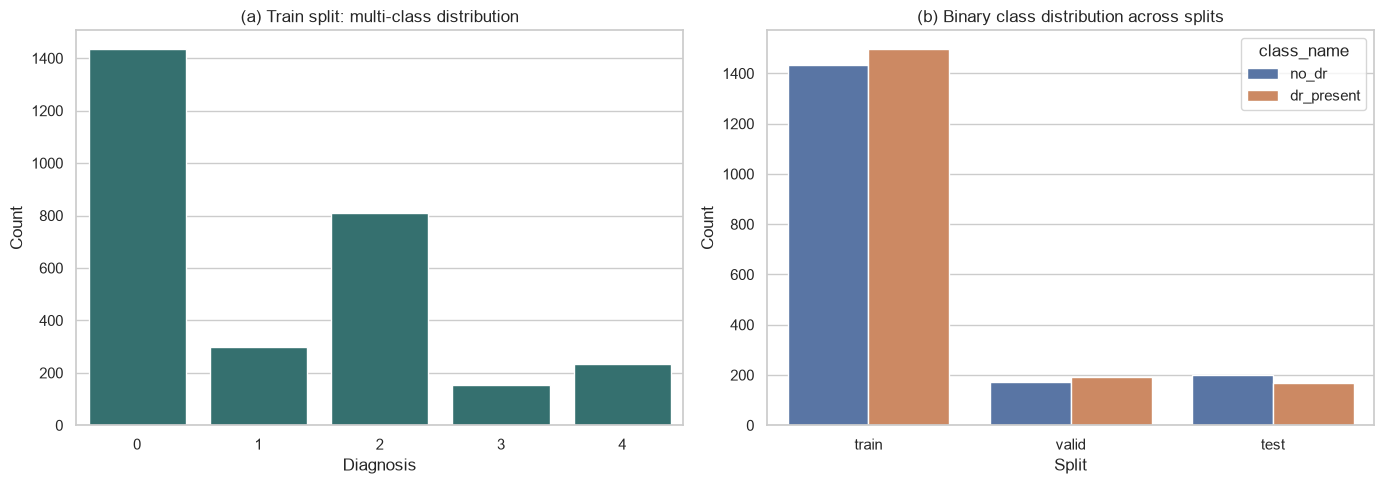

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

multi_counts = train_df["diagnosis"].value_counts().sort_index()
sns.barplot(x=multi_counts.index, y=multi_counts.values, ax=axes[0], color="#2b7a78")
axes[0].set_title("(a) Train split: multi-class distribution")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Count")

binary_long = summary.melt(
    id_vars="split",
    value_vars=["no_dr", "dr_present"],
    var_name="class_name",
    value_name="count",
)
sns.barplot(data=binary_long, x="split", y="count", hue="class_name", ax=axes[1])
axes[1].set_title("(b) Binary class distribution across splits")
axes[1].set_xlabel("Split")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


**Figure 1.1. Class distribution analysis for the APTOS 2019 dataset: (a) original severity labels in the training split, (b) binary class balance across train, validation, and test splits**


In [6]:
def build_image_path(image_dir: Path, image_id: str) -> Path:
    return image_dir / f"{image_id}.png"


def count_missing_images(df: pd.DataFrame, image_dir: Path) -> int:
    missing = 0
    for image_id in df["id_code"]:
        if not build_image_path(image_dir, image_id).exists():
            missing += 1
    return missing


missing_summary = pd.DataFrame(
    {
        "split": ["train", "valid", "test"],
        "missing_images": [
            count_missing_images(train_df, train_images_dir),
            count_missing_images(valid_df, valid_images_dir),
            count_missing_images(test_df, test_images_dir),
        ],
    }
)

missing_summary


,split,missing_images
0,train,0
1,valid,0
2,test,0


**Table 1.3. Number of missing retinal images detected in each dataset split**


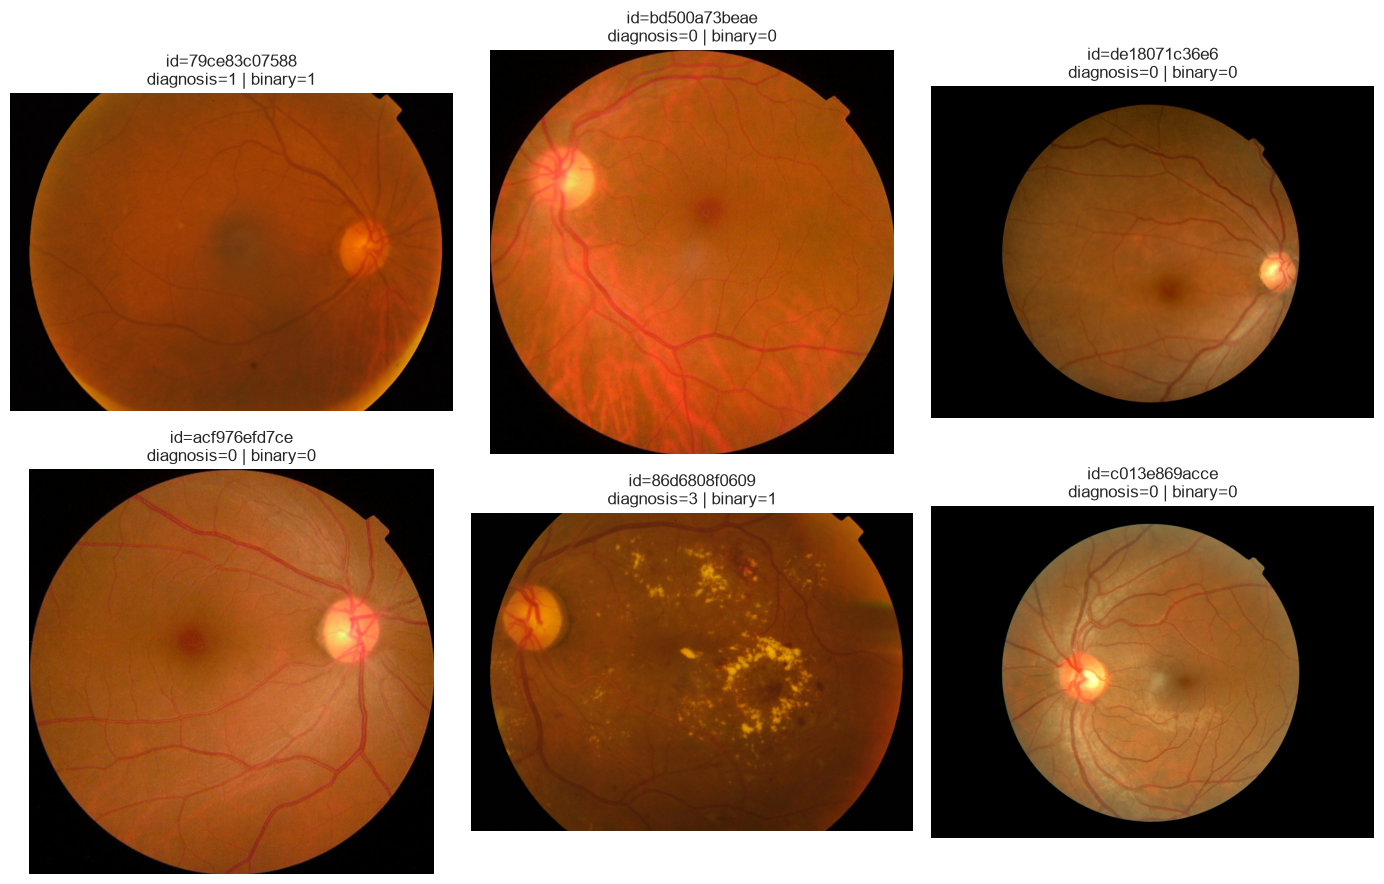

In [7]:
def show_samples(df: pd.DataFrame, image_dir: Path, n: int = 6, random_state: int = 42) -> None:
    sample_df = df.sample(n=min(n, len(df)), random_state=random_state).reset_index(drop=True)
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        image_path = build_image_path(image_dir, row["id_code"])
        image = Image.open(image_path).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"id={row['id_code']}\n"
            f"diagnosis={row['diagnosis']} | binary={row['binary_label']}"
        )
        ax.axis("off")

    for ax in axes[len(sample_df):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_samples(train_df, train_images_dir)


**Image 1.1. Random retinal fundus image samples from the training split with original diagnosis labels and binary labels**


## Next Step

If everything looks correct, the next project step is:

1. keep `binary classification` as the thesis baseline;
2. train the first `ResNet18` model;
3. evaluate accuracy, precision, recall, F1, and ROC-AUC;
4. later add `Grad-CAM` visual explanations.
